# Multi-Fidelity Neural Network Tuning: Forrester Function

Example is based on the 2007 paper "Multi-fidelity optimization via surrogate modelling" by Forrester, Sobester, and Keane. This presents some fiddling with the hyperparameters of the functions and it's effect on the high fidelity function fit.

In [5]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging
import multi_fidelity_functions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Introduce the example function

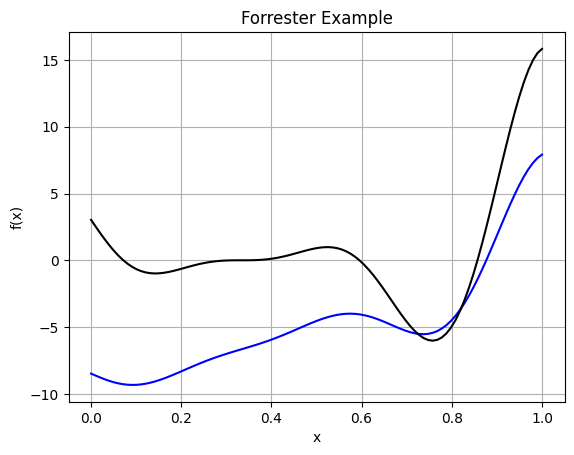

In [6]:
import multi_fidelity_functions
import matplotlib.pyplot as plt
import matplotlib.cm as cm

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name = mf_example.name)
plt.grid()
plt.show()

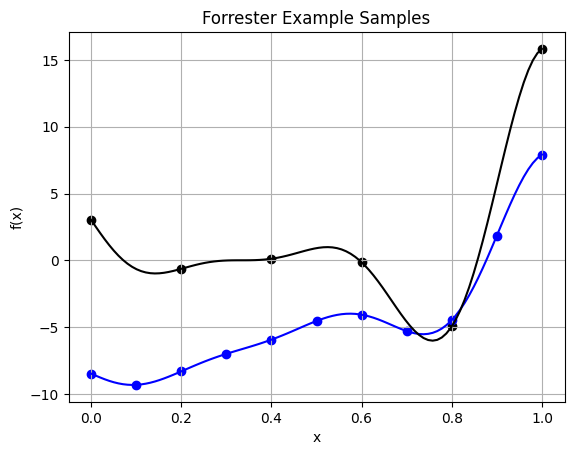

In [7]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11 # number of low fidelity points
n_hf = 6 # number of high fidelity points
n_test = 40 # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()



## Multi-Fidelity Neural Network Fit Training Variance

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

This experiment aims to compare the network for training variance with the same inputs to show the stability of the current hyperparameter set.

In [9]:
# Convert to tensors here
X_lf_tensor = torch.from_numpy(X_lf)
y_lf_tensor = torch.from_numpy(y_lf)

X_hf_tensor = torch.from_numpy(X_hf)
y_hf_tensor = torch.from_numpy(y_hf)

X_test_tensor = torch.from_numpy(X_test)
y_lf_test_tensor = torch.from_numpy(y_lf_test)
y_hf_test_tensor = torch.from_numpy(y_hf_test)

learning_rates = [1.0, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001]
run_number = np.linspace(1,5,5, dtype=np.int32)

forrester_mfnn_model_array = [mfsnn.MultiFidelityNN(
    X_lf=X_lf_tensor,
    y_lf=y_lf_tensor,
    X_lf_test=X_test_tensor,
    y_lf_test=y_lf_test_tensor,
    X_hf=X_hf_tensor,
    y_hf=y_hf_tensor,
    X_hf_test=X_test_tensor,
    y_hf_test=y_hf_test_tensor,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)for rn in run_number]

----Progress Update----
Epoch: 0 

Training Error: 2.6293962001800537 

----Progress Update----
Epoch: 1 

Training Error: 2.093480110168457 

----Progress Update----
Epoch: 2 

Training Error: 1.0577237606048584 

----Progress Update----
Epoch: 3 

Training Error: 0.7343938946723938 

----Progress Update----
Epoch: 4 

Training Error: 0.6286215782165527 

----Progress Update----
Epoch: 5 

Training Error: 0.5654622912406921 

----Progress Update----
Epoch: 6 

Training Error: 0.526441216468811 

----Progress Update----
Epoch: 7 

Training Error: 0.49400508403778076 

----Progress Update----
Epoch: 8 

Training Error: 0.46977499127388 

----Progress Update----
Epoch: 9 

Training Error: 0.4498778283596039 

----Progress Update----
Epoch: 10 

Training Error: 0.4180474579334259 

----Progress Update----
Epoch: 11 

Training Error: 0.27170583605766296 

----Progress Update----
Epoch: 12 

Training Error: 0.17902199923992157 

----Progress Update----
Epoch: 13 

Training Error: 0.12774789

TypeError: next() takes no keyword arguments

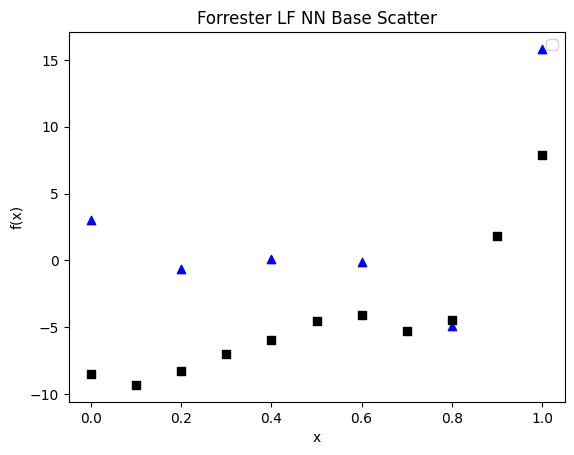

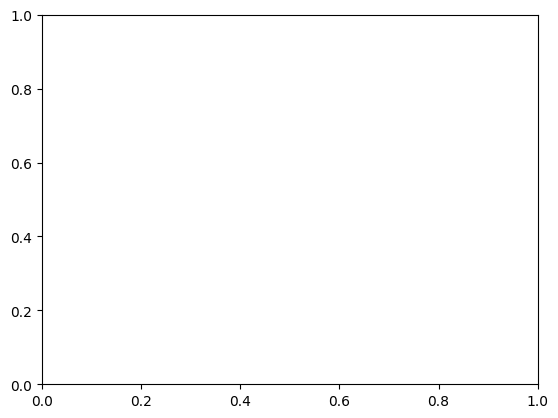

In [ ]:
# Compare Plots of LF and MF NN Data Fits Over Random Training Scatter
def GenerateComparisonPlots(
    forrester_mfnn_model_array: mfsnn.MultiFidelityNN, name_append=""
):
    # Generate Sample Points for the comparison plots
    X_check = np.linspace(0, 1.0, 300, endpoint=True, dtype=np.float32).reshape(-1, 1)
    X_check_tensor = torch.from_numpy(X_check)

    # Plot 1 - LF NN Scatter Plot
    plot_name = "Forrester LF NN Base Scatter" + name_append
    colors = iter(cm.rainbow(np.linspace(0, 1, len(run_number))))

    # Plot Model Data
    forrester_mfnn_model_array[0].plot_data(plot_name)

    fig = plt.figure()
    ax = fig.add_subplot()
    for i, rn in enumerate(run_number):
        ax = forrester_mfnn_model_array[i].low_fidelity_nn.plot_model(
            mf_example.bounds, name=plot_name, label=str(rn), color=next(colors), ax=ax
        )
    plt.grid()
    plt.show()

    # Plot 2 - MF NN Scatter Plot
    plot_name = "Forrester MFNN Base Scatter" + name_append  # Plot Model Data
    forrester_mfnn_model_array[0].plot_data(plot_name)
    colors = iter(cm.rainbow(np.linspace(0, 1, len(run_number))))

    fig = plt.figure()
    ax = fig.add_subplot()
    # forrester_mfnn_model_array.plot_model(X_check_tensor, name=plot_name, color="blue", label="MFNN")
    for i, rn in enumerate(run_number):
        ax = forrester_mfnn_model_array[i].plot_model(
            mf_example.bounds, name=plot_name, label=str(rn), color=next(colors), ax=ax
        )
    plt.grid()
    plt.show()

    # # Plot 3 - LF NN Training Scatter Plot
    # plot_name = "LF Training Error" + name_append
    # colors = iter(cm.rainbow(np.linspace(0, 1, len(run_number))))

    # fig = plt.figure()
    # ax = fig.add_subplot()
    # for i, rn in enumerate(run_number):
    #     ax = forrester_mfnn_model_array[i].low_fidelity_nn.plot_training_error(
    #         name=plot_name, ax=ax
    #     )
    # plt.yscale("log")
    # plt.legend("")
    # plt.grid()
    # plt.show()

    # # Plot 4 - MF NN Training Scatter Plot
    # plot_name = "MF Training Error" + name_append
    # colors = iter(cm.rainbow(np.linspace(0, 1, len(run_number))))

    # fig = plt.figure()
    # ax = fig.add_subplot()
    # for i, rn in enumerate(run_number):
    #     ax = forrester_mfnn_model_array[i].high_fidelity_nn.plot_training_error(
    #         name=plot_name, ax=ax
    #     )
    # plt.yscale("log")
    # plt.legend("")
    # plt.grid()
    # plt.show()

    # # Plot 5 - Alpha Parameter Training
    # plot_name = "MF Training Error"
    # colors = iter(cm.rainbow(np.linspace(0, 1, len(run_number))))

    # fig = plt.figure()
    # ax = fig.add_subplot()
    # for i, rn in enumerate(run_number):
    #     ax = forrester_mfnn_model_array[i].high_fidelity_nn.plot_alpha_history(
    #         name=plot_name
    #     )
    # plt.yscale("log")
    # plt.legend("")
    # plt.grid()
    # plt.show()


GenerateComparisonPlots(forrester_mfnn_model_array)

In [ ]:
# Convert to tensors here
X_lf_tensor = torch.from_numpy(X_lf)
y_lf_tensor = torch.from_numpy(y_lf)

X_hf_tensor = torch.from_numpy(X_hf)
y_hf_tensor = torch.from_numpy(y_hf)

X_test_tensor = torch.from_numpy(X_test)
y_lf_test_tensor = torch.from_numpy(y_lf_test)
y_hf_test_tensor = torch.from_numpy(y_hf_test)

run_number = np.linspace(1,5,5, dtype=np.int32)
lr_mf = 0.001
forrester_mfnn_model_array_a001 = [mfsnn.MultiFidelityNN(
    X_lf=X_lf_tensor,
    y_lf=y_lf_tensor,
    X_lf_test=X_test_tensor,
    y_lf_test=y_lf_test_tensor,
    X_hf=X_hf_tensor,
    y_hf=y_hf_tensor,
    X_hf_test=X_test_tensor,
    y_hf_test=y_hf_test_tensor,
    lf_nn_dim=[20, 20, 20],
    hf_linear_nn_dim=[10],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=5000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf = 0.001,
    wd_mf=0.01,
)for rn in run_number]

In [ ]:
# Compare Plots of LF and MF NN Data Fits Over Random Training Scatter

GenerateComparisonPlots(forrester_mfnn_model_array_a001, name_append=" Alpha 0.001")

In [ ]:
# Convert to tensors here
X_lf_tensor = torch.from_numpy(X_lf)
y_lf_tensor = torch.from_numpy(y_lf)

X_hf_tensor = torch.from_numpy(X_hf)
y_hf_tensor = torch.from_numpy(y_hf)

X_test_tensor = torch.from_numpy(X_test)
y_lf_test_tensor = torch.from_numpy(y_lf_test)
y_hf_test_tensor = torch.from_numpy(y_hf_test)

run_number = np.linspace(1,5,5, dtype=np.int32)
lr_mf = 0.005
forrester_mfnn_model_array_a005 = [mfsnn.MultiFidelityNN(
    X_lf=X_lf_tensor,
    y_lf=y_lf_tensor,
    X_lf_test=X_test_tensor,
    y_lf_test=y_lf_test_tensor,
    X_hf=X_hf_tensor,
    y_hf=y_hf_tensor,
    X_hf_test=X_test_tensor,
    y_hf_test=y_hf_test_tensor,
    lf_nn_dim=[20, 20, 20],
    hf_linear_nn_dim=[10],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=5000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf = 0.001,
    wd_mf=0.01,
)for rn in run_number]

In [ ]:
# Compare Plots of LF and MF NN Data Fits Over Random Training Scatter

GenerateComparisonPlots(forrester_mfnn_model_array_a005, name_append=" Alpha 0.005")
